# ***CT5120: Introduction to NLP***

# ***Assignment 1: Hate Speech Classification*** (Total 100 marks)
This assignment is focused on Hate Speech Classification from social media comments.

---

###  **Student Details**

Enter your

**Name: Arul Goma Vignesh Skanda**

**Student ID: 26235812**.

---

>  <font color="red">**Disclaimer:** This assignment may contain hate speech and offensive content, strictly for academic purposes. </font>

---
 **Deadline:** **`01:45 PM, 09th October, 2026`** (Ireland Time)

 **Submission Format:** `.ipynb`

 **Individual Assignment:** This is an individual assignment - your work must be your own.

<!-- ---

###  Academic Integrity

<font color="red">**Strictly no Generative AI.**</font> Do the assignment by yourself - write code and answers fully in your own words, without using AI tools.

<font color="red">**Note:**</font> You must **disable the AI features on Google Colab** before working on this assignment.
 Guide: [How to disable AI in Colab](https://youtu.be/qrGZv8nPh1o) -->



---

###  **In-Lab Grading — "Defend Your Work!**"

Think of this as a **mini viva** — you built it, so you should be able to talk through it.

| | |
|---|---|
|  **When** | `September 25th`, `October 2nd` & `October 9th, 2026` [12:00 PM to 02:00 PM] |
|  **What** | A short, friendly Q&A with your TAs |
|  **How** | TAs will ask you a few questions about your notebook |

>  **Pro tip:** You don't need to memorise every line. If you understand *What, How, & Why* you made each decision, you'll breeze through this.

No surprises, no trick questions - just show us it's genuinely **your work, and your understanding.**



---

###  **Task Roadmap**

Here's what you'll be building, step by step:

| # | Section | Focus |
|---|---|---|
| 1️ | **Dataset & EDA** | Pick a dataset, justify it, explore the classes (One example provided ) |
| 2️ | **Training & Evaluation** | Train a classifier, evaluate it properly |
| 3️ | **Improve It** | Tune the *same* model, prove it got better |

Each section builds on the last - so a solid dataset and clean features in Sections 1 will make Sections 2-3 much smoother.

---

###  Important

<!-- -  Only edit cells marked `# YOUR CODE HERE` or `# YOUR ANSWER HERE` — leave everything else untouched. -->
-  Run **all cells top-to-bottom** with no errors before submitting.
-  **Google Colab** is recommended to avoid dependency issues.

---

---
# **Dataset Details**

The dataset can be divided into **three parts**: **Training**, **Development (Dev)**, and **Test** sets.  

1. **Training set**  
   - Used to **train your model** (learn patterns from the data).  
   - This is the largest portion of the dataset.  

2. **Development (Dev) set**  
   - A small part of the training data that is **held out**.  
   - Used to **validate your model** while training and for **hyperparameter tuning**.  
   - Helps avoid overfitting (your model performing well on training but poorly on unseen data).  

3. **Test set**  
   - Contains **unlabeled data** (labels are hidden).
   - Used only for **final evaluation** of your model.  
   - You will generate a **prediction file** for this set and submit it.  

---

# Installing and Importing Packages

> **Note:** This setup cell is not directly graded. You may install and import any Python packages required for your experiments.  
> Commonly used libraries for this assignment may include `pandas`, `numpy`, `matplotlib`, `scikit-learn`, and relevant NLP libraries.

In [ ]:
!pip install -q datasets scikit-learn pandas matplotlib seaborn

In [ ]:
import re, html, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from datasets import load_dataset
from sklearn.model_selection import train_test_split, GridSearchCV, PredefinedSplit
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

---

# **Section 1: Dataset Selection & Exploratory Data Analysis**

### `Total = 30 marks`

Before building your classification model, select a suitable **hate-speech classification dataset** and explore its main characteristics.

> **Note:** You may use one of the example datasets provided in Task 1a, or select another appropriate publicly available dataset.

| Task | What you'll do | Marks |
|---|---|---|
| **1a** | Select and load a dataset, and prepare Train / Dev / Test splits | `5` |
| **1b** | Plot the **class distribution** using a suitable visualisation | `10` |
| **1c** | Carry out **Exploratory Data Analysis (EDA)** relevant to your dataset, such as text length, vocabulary size, common n-grams, or other informative characteristics | `5` |
| **1d** | Explain your **dataset selection** and the main findings from your EDA | `10` |

> A clear understanding of the dataset will help you make better decisions in the later modelling and evaluation sections.

---

## **1a: Dataset** (5 marks)

Select and load **one suitable hate-speech classification dataset** for this assignment.

> **Note:** You may choose **one of the example datasets listed below**, or you may use **another appropriate publicly available dataset** of your choice.

Example datasets:

1. https://huggingface.co/datasets/christinacdl/binary_hate_speech  
2. https://huggingface.co/datasets/tdavidson/hate_speech_offensive  
3. https://huggingface.co/datasets/tweets-hate-speech-detection/tweets_hate_speech_detection  
4. https://huggingface.co/datasets/badmatr11x/hate-offensive-speech  

If you choose a different dataset, it should contain:

- textual input data;
- clearly defined class labels;
- enough examples for model training and evaluation.

Use the dataset's existing **Train / Dev / Test splits** where available. If suitable splits are not provided, create them yourself.

Tutorial: [Loading a dataset from Hugging Face](https://huggingface.co/docs/datasets/load_hub)

In [ ]:
ds = load_dataset("tdavidson/hate_speech_offensive")
print(ds)
df = ds["train"].to_pandas()
print(df.shape)
print(df.columns.tolist())
df.head()

README.md:   0%|          | 0.00/5.92k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.63MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/24783 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['count', 'hate_speech_count', 'offensive_language_count', 'neither_count', 'class', 'tweet'],
        num_rows: 24783
    })
})
(24783, 6)
['count', 'hate_speech_count', 'offensive_language_count', 'neither_count', 'class', 'tweet']


,count,hate_speech_count,offensive_language_count,neither_count,class,tweet
0,3,0,0,3,2,!!! RT @mayasolovely: As a woman you shouldn't...
1,3,0,3,0,1,!!!!! RT @mleew17: boy dats cold...tyga dwn ba...
2,3,0,3,0,1,!!!!!!! RT @UrKindOfBrand Dawg!!!! RT @80sbaby...
3,3,0,2,1,1,!!!!!!!!! RT @C_G_Anderson: @viva_based she lo...
4,6,0,6,0,1,!!!!!!!!!!!!! RT @ShenikaRoberts: The shit you...


In [ ]:
LABELS = {0: "hate_speech", 1: "offensive", 2: "neither"}
df["label_name"] = df["class"].map(LABELS)
print(df["class"].value_counts())
print(df["class"].value_counts(normalize=True).round(4)) #normalize=true means it gives proportion of a class (0-> 5000/10000)

train_df, temp_df = train_test_split(
    df, test_size=0.20, stratify=df["class"], random_state=RANDOM_STATE)
dev_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df["class"], random_state=RANDOM_STATE)

for name, part in [("train", train_df), ("dev", dev_df), ("test", test_df)]:
    print(f"{name:6s} {len(part):6d}", part["class"].value_counts(normalize=True).round(3).to_dict())

class
1    19190
2     4163
0     1430
Name: count, dtype: int64
class
1    0.7743
2    0.1680
0    0.0577
Name: proportion, dtype: float64
train   19826 {1: 0.774, 2: 0.168, 0: 0.058}
dev      2478 {1: 0.774, 2: 0.168, 0: 0.058}
test     2479 {1: 0.774, 2: 0.168, 0: 0.058}


## **1b: Class Distribution** (10 marks)

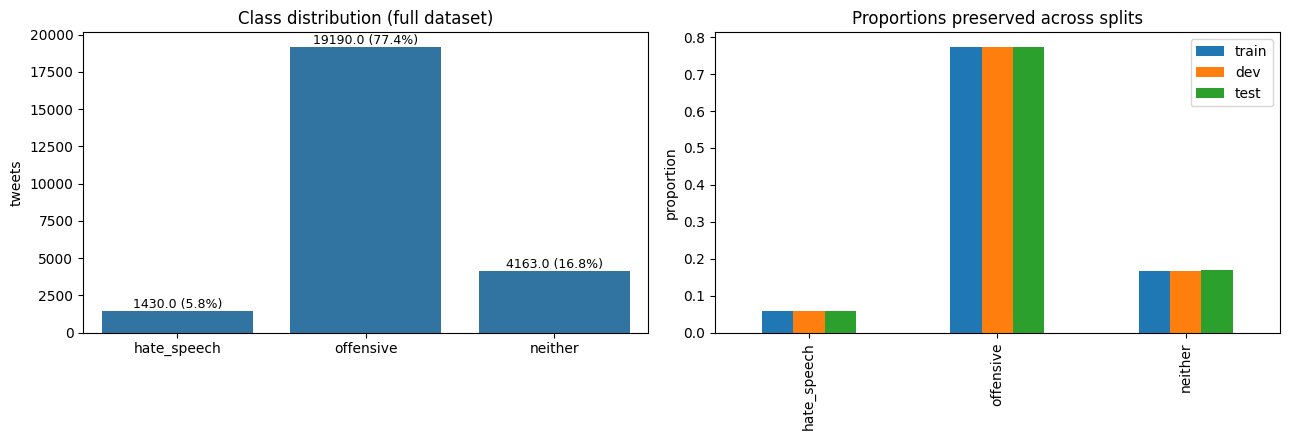

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

order = ["hate_speech", "offensive", "neither"]
#1st graph
sns.countplot(data=df, x="label_name", order=order, ax=axes[0])
axes[0].set_title("Class distribution (full dataset)")
axes[0].set_xlabel(""); axes[0].set_ylabel("tweets")
total = len(df)
for p in axes[0].patches:
    axes[0].annotate(f"{p.get_height()} ({p.get_height()/total:.1%})",
                     (p.get_x() + p.get_width()/2, p.get_height()),
                     ha="center", va="bottom", fontsize=9)
#2nd graph
split_counts = pd.concat([
    train_df["label_name"].value_counts(normalize=True).rename("train"),
    dev_df["label_name"].value_counts(normalize=True).rename("dev"),
    test_df["label_name"].value_counts(normalize=True).rename("test"),
], axis=1).loc[order]
split_counts.plot(kind="bar", ax=axes[1])
axes[1].set_title("Proportions preserved across splits")
axes[1].set_ylabel("proportion"); axes[1].set_xlabel("")

plt.tight_layout(); plt.show()

## **1c: Exploratory Data Analysis (EDA)** (5 marks)

             n_chars                                             n_words  \
               count  mean   std  min   25%   50%    75%    max    count   
label_name                                                                 
hate_speech   1430.0  84.6  40.5  5.0  49.0  82.0  121.0  254.0   1430.0   
neither       4163.0  94.9  41.1  7.0  60.0  97.0  132.0  522.0   4163.0   
offensive    19190.0  83.5  41.5  5.0  50.0  78.0  115.0  754.0  19190.0   

                                                    
             mean  std  min  25%   50%   75%   max  
label_name                                          
hate_speech  13.9  7.0  1.0  8.0  13.5  20.0  32.0  
neither      14.9  6.8  1.0  9.0  15.0  20.0  52.0  
offensive    14.0  6.8  1.0  8.0  13.0  19.0  36.0  


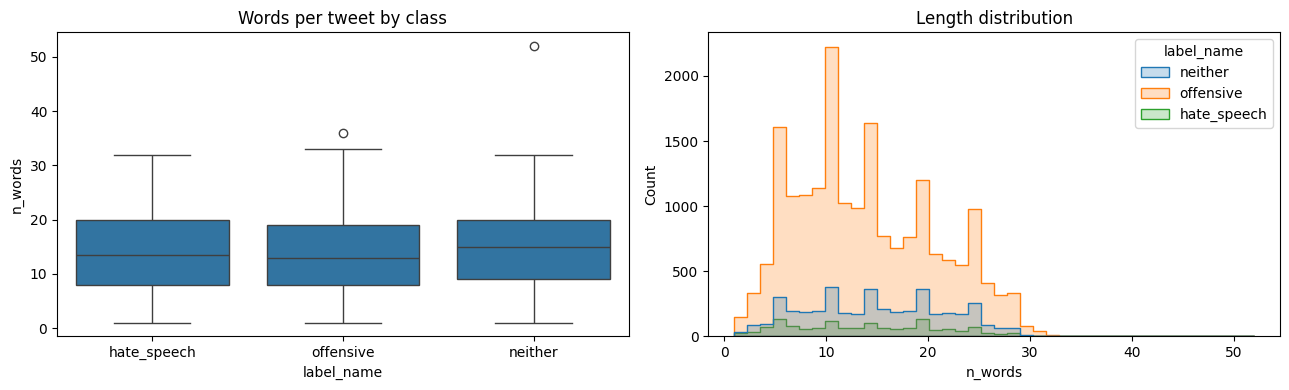

In [ ]:
df["n_chars"] = df["tweet"].str.len()
df["n_words"] = df["tweet"].str.split().str.len()
print(df.groupby("label_name")[["n_chars", "n_words"]].describe().round(1))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=df, x="label_name", y="n_words", order=order, ax=axes[0])
axes[0].set_title("Words per tweet by class")
sns.histplot(data=df, x="n_words", hue="label_name", bins=40, element="step", ax=axes[1])
axes[1].set_title("Length distribution")
plt.tight_layout(); plt.show()

In [ ]:
# unique words are picked and duplicates are not included. 30989 is the unique words in the dataset and vocabulary_size is number of unique words.
cv = CountVectorizer()
cv.fit(train_df["tweet"])
print("Vocabulary size (train, raw):", len(cv.vocabulary_))

# metrics of the noise in the data.
print("contains URL:      ", train_df["tweet"].str.contains(r"http", case=False).mean().round(3))
print("contains @mention: ", train_df["tweet"].str.contains(r"@\w+").mean().round(3))
print("retweets (RT):     ", train_df["tweet"].str.contains(r"^RT\b").mean().round(3))
print("HTML entities:     ", train_df["tweet"].str.contains(r"&(amp|lt|gt|#\d+);").mean().round(3))
print("exact duplicates:  ", train_df["tweet"].duplicated().sum())

Vocabulary size (train, raw): 30989
contains URL:       0.122
contains @mention:  0.572
retweets (RT):      0.261
HTML entities:      0.266
exact duplicates:   0


In [ ]:
# Most frequent bigrams per class
def top_ngrams(texts, ngram_range=(2, 2), n=12):
    v = CountVectorizer(ngram_range=ngram_range, stop_words="english", min_df=2) #we are removing common english stop words, only keep min_df=2 bigrams in atleast 2 tweets or document.
    X = v.fit_transform(texts) #converts the texts into counts
    freqs = np.asarray(X.sum(axis=0)).ravel() #How many times did each bigram appear across ALL tweets?
    vocab = np.array(v.get_feature_names_out())
    idx = freqs.argsort()[::-1][:n] #Find the most frequent bigrams.
    return pd.Series(freqs[idx], index=vocab[idx]) #The most frequent bigrams and how many times each occurred.

for cls in order:
    print(f"\n--- top bigrams: {cls} ---")
    print(top_ngrams(train_df.loc[train_df["label_name"] == cls, "tweet"]))


--- top bigrams: hate_speech ---
white trash       45
128514 128514     42
ass nigga         16
look like         14
bitch ass         11
fucking faggot     9
faggot ass         9
128514 128557      7
ass bitch          7
bitch nigga        7
don like           7
ass niggas         7
dtype: int64

--- top bigrams: offensive ---
128514 128514    1279
128557 128557     191
bitch ass         183
like bitch        174
yo bitch          155
bad bitch         143
ass bitch         142
look like         123
128175 128175     113
bad bitches       110
fuck bitch        105
bitch http        101
dtype: int64

--- top bigrams: neither ---
http 8230        75
9733 9733        64
128514 128514    61
flappy bird      32
charlie crist    31
128557 128557    23
look like        23
charlie sheen    22
derek jeter      21
trash http       20
charlie baker    20
early bird       20
dtype: int64


## **1d: Explanation** (10 marks)

**Question:** Explain your dataset selection and your Exploratory Data Analysis (EDA) process.

Your answer should cover:
- **Why you selected this dataset?**
- **The EDA process carried out in Tasks 1a to 1c**. what you looked at (class distribution, text statistics, etc.).

Your explanation should be written in your own words and should not exceed **50 words** in length.

```
# I chose davidson dataset because it didn't need much of preprocessing of the dataset. My EDA examined class distribution, bigrams, vocabulary size, noise characteristics such as links(URL), mention, retweets etc.During the data analysis i found out that offensive speech has the largest chunk in the data and the others are comparatively low.



```

---

#  **Section 2**: Feature Extraction, Model Training & Evaluation

### `Total = 40 marks`

Time to build your baseline model. In this section, you will convert the text into suitable numerical features or embeddings, train a classical machine-learning classifier, and evaluate its performance using appropriate metrics.

| Task   | What you'll do                                                                                                                                                            | Marks |
| ------ | ------------------------------------------------------------------------------------------------------------------------------------------------------------------------- | ----: |
| **2a** | Perform **feature extraction** using a suitable technique |  `10` |
| **2b** | Train a suitable **classical ML baseline classifier** using the extracted features                                                                                        |  `10` |
| **2c** | **Predict and evaluate** the model using multiple appropriate evaluation metrics                                                                                          |  `10` |
| **2d** | Explain your **feature extraction method, model choice, evaluation metrics, and results**                                                                                 |  `10` |

>  Choose a feature representation and classical machine-learning model that are suitable for your dataset. Your goal here is to establish a clear and well-evaluated **baseline model**. You will improve this same model in Section 3.

---


## **2a: Feature Extraction / Text Representation** (10 marks)
Use a suitable feature extraction or text representation technique to convert the text data into numerical features that can be used by a classical machine-learning model.

* You may use an appropriate method such as: Bag-of-Words, TF-IDF, Word2Vec, FastText or another suitable feature representation method

Your implementation should clearly show how the training, validation, and test data are transformed.

In [ ]:
URL_RE     = re.compile(r"http\S+|www\.\S+")
MENTION_RE = re.compile(r"@\w+")
RT_RE      = re.compile(r"^RT[\s:]+", flags=re.IGNORECASE)
WS_RE      = re.compile(r"\s+") #white space, unnecassary spaces

def clean_tweet(t):
    t = html.unescape(html.unescape(t))
    t = RT_RE.sub(" ", t)
    t = URL_RE.sub(" url ", t)
    t = MENTION_RE.sub(" user ", t)
    return WS_RE.sub(" ", t).strip()

for part in (train_df, dev_df, test_df):
    part["clean"] = part["tweet"].apply(clean_tweet)

print(train_df[["tweet", "clean"]].head(3).to_string())

                                                                   tweet                                  clean
21283                                            Talking Angela is a hoe                Talking Angela is a hoe
12619                              Lol they tricking niccas left n right  Lol they tricking niccas left n right
975    &#128514;&#128514; bitches get stuff done. http://t.co/GvFpk65ah5         😂😂 bitches get stuff done. url


In [ ]:
vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=2, #minimum 2 appearances
    max_df=0.90, #ignoring terms appearing in more than 90% doc
    sublinear_tf=True,
    strip_accents="unicode",
    lowercase=True,
)

X_train = vectorizer.fit_transform(train_df["clean"])   # fit ONLY on train, fit + transform
X_dev   = vectorizer.transform(dev_df["clean"]) #transform text into numerical vectors
X_test  = vectorizer.transform(test_df["clean"]) #transform text into numerical vectors

y_train, y_dev, y_test = train_df["class"], dev_df["class"], test_df["class"] #gives class for each tweet in train, dev and test
print(X_train.shape, X_dev.shape, X_test.shape) #input

(19826, 32362) (2478, 32362) (2479, 32362)


## **2b: Classifier Model** (10 marks)
Train a suitable classical machine-learning classifier using the features produced in Task 2a.

In [ ]:
baseline = LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)
baseline.fit(X_train, y_train) #x is information and y is answer

LogisticRegression(max_iter=2000, random_state=42)

## **2c: Predict & Evaluate** (10 marks)
Use your trained model to make predictions on the test set and evaluate its performance using multiple suitable evaluation metrics.


===== BASELINE — dev =====
Accuracy      : 0.8890
Macro F1      : 0.6560
Weighted F1   : 0.8711
              precision    recall  f1-score   support

 hate_speech      0.690     0.140     0.233       143
   offensive      0.894     0.978     0.934      1919
     neither      0.877     0.738     0.802       416

    accuracy                          0.889      2478
   macro avg      0.820     0.618     0.656      2478
weighted avg      0.879     0.889     0.871      2478


===== BASELINE — test =====
Accuracy      : 0.8927
Macro F1      : 0.6617
Weighted F1   : 0.8756
              precision    recall  f1-score   support

 hate_speech      0.667     0.140     0.231       143
   offensive      0.901     0.974     0.936      1919
     neither      0.866     0.775     0.818       417

    accuracy                          0.893      2479
   macro avg      0.811     0.630     0.662      2479
weighted avg      0.881     0.893     0.876      2479



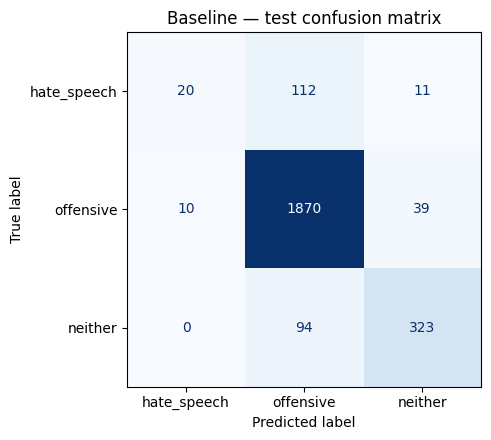

In [ ]:
def evaluate(model, X, y, title):
    pred = model.predict(X) #model predicts
    print(f"\n===== {title} =====")
    print(f"Accuracy      : {accuracy_score(y, pred):.4f}")
    print(f"Macro F1      : {f1_score(y, pred, average='macro'):.4f}")
    print(f"Weighted F1   : {f1_score(y, pred, average='weighted'):.4f}") #we calculate f1 but we give priority to larger class
    print(classification_report(y, pred, target_names=order, digits=3))
    return pred

pred_dev_base  = evaluate(baseline, X_dev,  y_dev,  "BASELINE — dev")
pred_test_base = evaluate(baseline, X_test, y_test, "BASELINE — test")

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred_test_base),
                       display_labels=order).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Baseline — test confusion matrix"); plt.tight_layout(); plt.show()

## **2d: Explanation** (10 marks)

**Question:** Explain your feature representation, baseline model choice, and evaluation results.

Your answer should cover:
* **Feature extraction** - explain which feature extraction or embedding method
you used, how it represents the text, and why it is suitable for your dataset.
* **Why you chose this classifier** - explain why the selected model is suitable for your feature representation and why it provides a reasonable baseline.
* **The metrics you reported in Task 2c** - explain what the selected metrics measure and why using only a single metric, such as accuracy, may be misleading.
* **Your results** - briefly discuss what the obtained scores indicate about the strengths and weaknesses of your baseline model.

Your explanation should be written in your own words and should not exceed **50 words** in length.

```
# I have used TF-IDF to reperesent the tweets numerically by assigning higher weights to words that are important within a tweet (in the dataset). I chose logistic regression because it works well with high dimensional TF-IDF feature and provides an effective baseline for the classification. I have also evaluated model using accuracy, precision, recall, F1 score and confusion matrix, the model performed well on the offensive class but frequently confused hatespeech with offensive speech showing wekaer performance on the smaller classes.



```

---

#  **Section 3**: Improving the Model
### `Total = 30 marks`

Your model works, now make it better. The catch: you must improve the **same model** from Section 2 (e.g. SVM → tuned SVM), not swap in a different classifier.

| Task | What you'll do | Marks |
|---|---|---|
| **3a** | **Improve** your baseline (same model type) | `10` |
| **3b** | **Predict & evaluate** using multiple suitable metrics | `10` |
| **3c** | Explain your **improvement approach** and **the metrics** | `10` |

>  Use the dev set to guide your improvements - hyperparameter tuning, class-imbalance handling, or adjusting your feature-extraction parameters are all fair game.

---

## **3a: Improve your model** (10 marks)

In [ ]:
X_td_text = pd.concat([train_df["clean"], dev_df["clean"]])
y_td      = pd.concat([train_df["class"], dev_df["class"]])
# -1 => never used for validation; 0 => the dev fold
test_fold = np.r_[np.full(len(train_df), -1), np.zeros(len(dev_df))]
ps = PredefinedSplit(test_fold)

pipe = Pipeline([
    ("tfidf", TfidfVectorizer(sublinear_tf=True, strip_accents="unicode")),
    ("clf",   LogisticRegression(max_iter=3000, random_state=RANDOM_STATE)),
])

param_grid = {
    "tfidf__ngram_range":  [(1, 1), (1, 2)], #single words, pair words
    "tfidf__min_df":       [1, 2, 3],
    "tfidf__max_df":       [0.9],
    "clf__C":              [0.1, 1, 5, 10], #small c stronger regularization (prevents overfitting)
    "clf__class_weight":   [None, "balanced"], #classes that have fewer examples (balanced)
}

gs = GridSearchCV(
    pipe,
    param_grid,
    scoring="f1_macro",
    cv=ps,
    n_jobs=-1,
    refit=True, #retrain using the winning settings
    verbose=1,
)
gs.fit(X_td_text, y_td)

print("Best macro-F1 on dev (held-out, during search):", round(gs.best_score_, 4))
print("Best params:", gs.best_params_)

improved = gs.best_estimator_
improved.fit(train_df["clean"], y_train)

Fitting 1 folds for each of 48 candidates, totalling 48 fits
Best macro-F1 on dev (held-out, during search): 0.7539
Best params: {'clf__C': 5, 'clf__class_weight': 'balanced', 'tfidf__max_df': 0.9, 'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 2)}


Pipeline(steps=[('tfidf',
                 TfidfVectorizer(max_df=0.9, ngram_range=(1, 2),
                                 strip_accents='unicode', sublinear_tf=True)),
                ('clf',
                 LogisticRegression(C=5, class_weight='balanced', max_iter=3000,
                                    random_state=42))])

## **3b: Predict & Evaluate** (10 marks)


--- IMPROVED ---
dev  acc 0.8910 | macro-F1 0.7539
test acc 0.8887 | macro-F1 0.7326
dev macro-F1 during search (model had not seen dev): 0.7539
              precision    recall  f1-score   support

 hate_speech      0.391     0.413     0.401       143
   offensive      0.947     0.918     0.932      1919
     neither      0.818     0.916     0.864       417

    accuracy                          0.889      2479
   macro avg      0.719     0.749     0.733      2479
weighted avg      0.893     0.889     0.890      2479

                  Baseline  Improved       Δ
Accuracy            0.8927    0.8887 -0.0040
Macro F1            0.6617    0.7326  0.0709
Weighted F1         0.8756    0.8902  0.0146
F1 (hate_speech)    0.2312    0.4014  0.1702


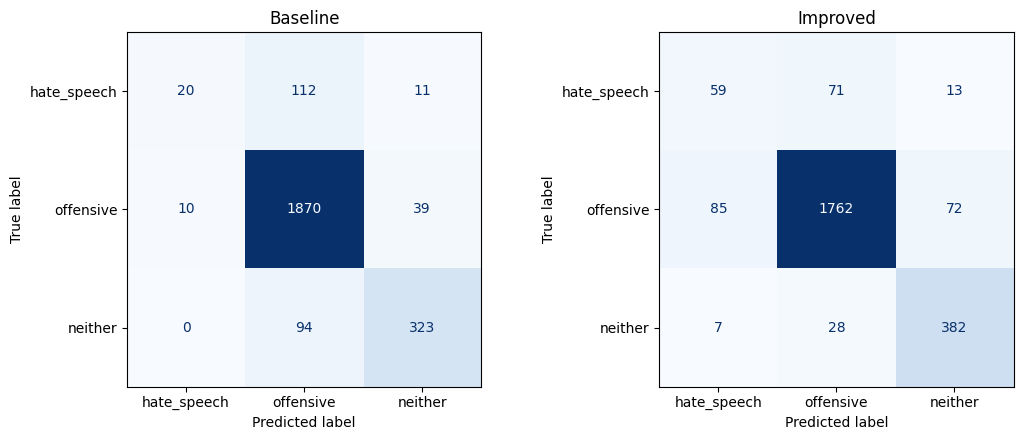

In [ ]:
print("\n--- IMPROVED ---")
pred_dev_imp  = improved.predict(dev_df["clean"]) #predicting with the improved model
pred_test_imp = improved.predict(test_df["clean"]) #same

print(f"dev  acc {accuracy_score(y_dev, pred_dev_imp):.4f} | macro-F1 {f1_score(y_dev, pred_dev_imp, average='macro'):.4f}")
print(f"test acc {accuracy_score(y_test, pred_test_imp):.4f} | macro-F1 {f1_score(y_test, pred_test_imp, average='macro'):.4f}")
print(f"dev macro-F1 during search (model had not seen dev): {gs.best_score_:.4f}")
print(classification_report(y_test, pred_test_imp, target_names=order, digits=3))

comparison = pd.DataFrame({
    "Baseline": [accuracy_score(y_test, pred_test_base),
                 f1_score(y_test, pred_test_base, average="macro"),
                 f1_score(y_test, pred_test_base, average="weighted"),
                 f1_score(y_test, pred_test_base, average=None)[0]],
    "Improved": [accuracy_score(y_test, pred_test_imp),
                 f1_score(y_test, pred_test_imp, average="macro"),
                 f1_score(y_test, pred_test_imp, average="weighted"),
                 f1_score(y_test, pred_test_imp, average=None)[0]],
}, index=["Accuracy", "Macro F1", "Weighted F1", "F1 (hate_speech)"]).round(4)
comparison["Δ"] = (comparison["Improved"] - comparison["Baseline"]).round(4)
print(comparison)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (p, t) in zip(axes, [(pred_test_base, "Baseline"), (pred_test_imp, "Improved")]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, p), display_labels=order).plot(
        ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(t)
plt.tight_layout(); plt.show()

## **3c: Explanation** (10 marks)

**Question:** Explain your improvement approach and your evaluation results.

Your answer should cover:
- **What you changed and why** - the specific improvement(s) you applied in Task 3a, and why you expected them to help, based on what you observed about the baseline in Section 2.
- **The metrics you reported in Task 3b** - how they compare to your baseline's (Task 2): did your improvement actually help, on which metric(s), and by how much? If some metrics improved while others didn't, discuss why that might be.

Your explanation should be written in your own words and should not exceed **50 words** in length.

```
# I improved the baseline by tuning TF-IDF and logistic regression parameters using gridsearchcv, and also changed the settings and increased the iteration form 2k to 3k to find the best model performance.



```

---

#  That's a wrap!

Thanks for working through this assignment. Double-check your cells run top-to-bottom with saved outputs, then upload to `Canvas` before **01:45 PM, October 9th, 2026**.

See you at the in-lab Q&A and for the grade!

---